In [1]:
#importing library
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import data_utils as du

In [2]:
#Importing the dataset
reg_path= "../../data/Regression_datasets/cybersecurity.csv"
reg_data= pd.read_csv(reg_path)
print(reg_data.head())

      traffic  packet_size  connections    latency
0  844.327631   572.023901           50  81.382959
1  407.046769   575.175261           45  51.087764
2  934.408999   637.236279           50  82.157486
3  854.848353   263.480506           59  74.089199
4  280.539247   580.274852           60  62.119639


In [3]:
#data exploration
du.data_exploration(reg_data)

DATA EXPLORATION
Shape of dataset: 10000 rows, 4 columns

Columns: ['traffic', 'packet_size', 'connections', 'latency']

Data Types:
 traffic        float64
packet_size    float64
connections      int64
latency        float64
dtype: object

Missing Values:
 traffic        0
packet_size    0
connections    0
latency        0
dtype: int64

Statistical Summary:
             traffic   packet_size   connections       latency
count  10000.000000  10000.000000  10000.000000  10000.000000
mean     550.133222    500.710268     50.065100     62.551425
std      259.622396     99.400992      7.082787     14.357393
min      100.008069    113.692075     20.000000     21.489861
25%      324.282700    433.327023     45.000000     51.267450
50%      551.025887    500.559580     50.000000     62.738399
75%      772.357738    567.591583     55.000000     73.626358
max      999.890919    857.905262     77.000000    103.265467


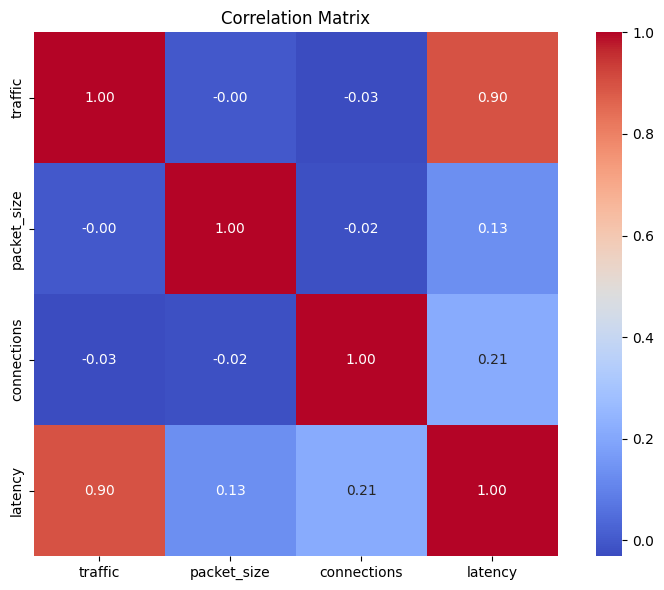

In [5]:
#data visualization
corr = du.get_correlation_matrix(reg_data)
du.plot_correlation_matrix(corr)

traffic is 90 linear relationship with latency. 20% connections linear relationship with latency









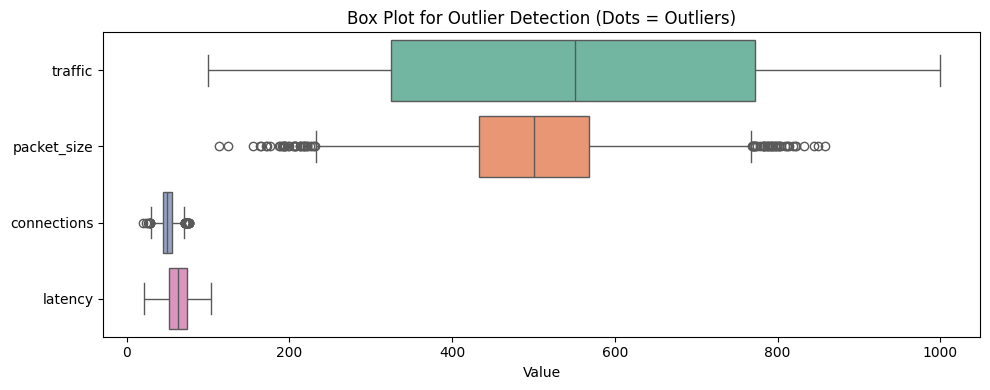

In [6]:
#check for outliers
cols = reg_data.columns
du.plot_boxplots(reg_data, cols)

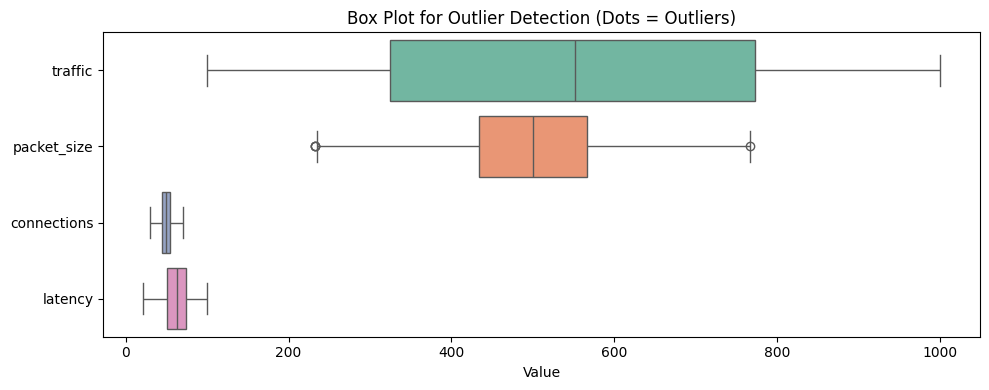

In [8]:
#clean outliers
reg_data_cleaned = du.remove_outliers_iqr(reg_data, cols)
du.plot_boxplots(reg_data_cleaned, cols)

In [9]:
#liner regression
X = reg_data_cleaned.drop('latency', axis=1)
y = reg_data_cleaned['latency']

In [11]:
model, mse, r2, y_test, y_pred = du.linear_regression_model(X, y)

Mean Squared Error: 23.6840
R-squared: 0.8833


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [14]:
#cross validation
cv_results = du.cross_validation(model,X, y, cv=5)

5-Fold Cross-Validation (r2): [0.87673251 0.88460552 0.87791035 0.88003775 0.87456041]
Average CV score: 0.8788 (± 0.0034)


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: i

Almost 88% accuracy gettting from linear regression


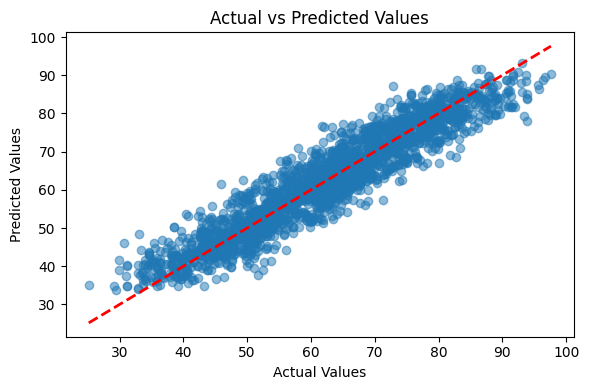

In [15]:
du.plot_actual_vs_predicted(y_test, y_pred)